===== CAMPUS ROUTE FINDER USING BFS =====

Available Locations:
1. Main Gate
2. Library
3. Canteen
4. Admin Block
5. Computer Lab
6. Auditorium
7. Classroom

Enter starting location: classroom
Enter destination location: main gate

Shortest Route:
Classroom -> Admin Block -> Library -> Main Gate

Number of Hops: 3
Number of Locations Visited in Route: 4


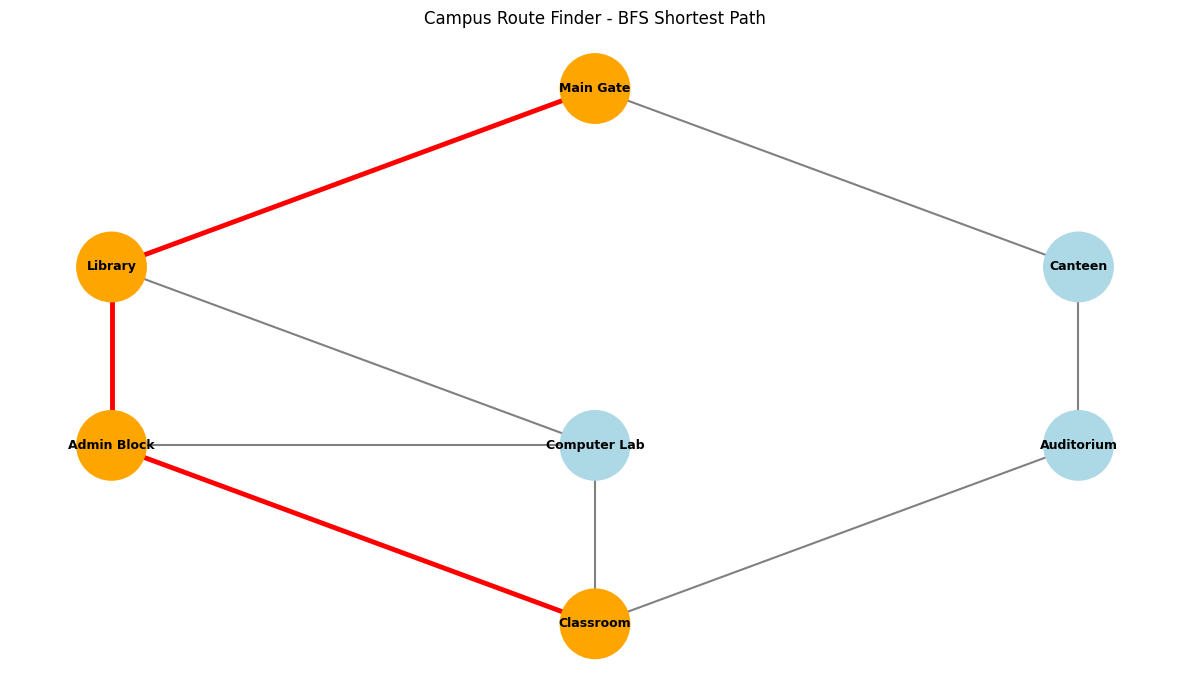

In [ ]:

# Campus Route Finder Using BFS
# Run this code directly in Google Colab

from collections import deque
import networkx as nx
import matplotlib.pyplot as plt

# Step 1: Define the campus as an unweighted graph
campus = {
    "Main Gate": ["Library", "Canteen"],
    "Library": ["Main Gate", "Admin Block", "Computer Lab"],
    "Canteen": ["Main Gate", "Auditorium"],
    "Admin Block": ["Library", "Computer Lab", "Classroom"],
    "Computer Lab": ["Library", "Admin Block", "Classroom"],
    "Auditorium": ["Canteen", "Classroom"],
    "Classroom": ["Admin Block", "Computer Lab", "Auditorium"]
}

# Step 2: Implement Breadth-First Search
def bfs_shortest_path(graph, start, destination):
    queue = deque([[start]])
    visited = {start}

    while queue:
        path = queue.popleft()
        current = path[-1]

        if current == destination:
            return path

        for neighbor in graph[current]:
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(path + [neighbor])

    return None

# Step 3: Display available campus locations
print("===== CAMPUS ROUTE FINDER USING BFS =====")
print("\nAvailable Locations:")

for i, location in enumerate(campus.keys(), start=1):
    print(f"{i}. {location}")

# Step 4: Get source and destination from the user
start = input("\nEnter starting location: ").strip().title()
destination = input("Enter destination location: ").strip().title()

# Step 5: Find and display the shortest route
if start not in campus or destination not in campus:
    print("\nInvalid location! Please enter a location from the list.")

else:
    path = bfs_shortest_path(campus, start, destination)

    if path:
        print("\nShortest Route:")
        print(" -> ".join(path))
        print("\nNumber of Hops:", len(path) - 1)
        print("Number of Locations Visited in Route:", len(path))

        # Step 6: Visualize the campus graph and route
        G = nx.Graph()

        for location, neighbors in campus.items():
            for neighbor in neighbors:
                G.add_edge(location, neighbor)

        # Fixed positions make the map easier to read
        positions = {
            "Main Gate": (0, 2),
            "Library": (-2, 1),
            "Canteen": (2, 1),
            "Admin Block": (-2, 0),
            "Computer Lab": (0, 0),
            "Auditorium": (2, 0),
            "Classroom": (0, -1)
        }

        route_edges = list(zip(path, path[1:]))
        route_nodes = set(path)

        plt.figure(figsize=(12, 7))

        # Draw all campus connections
        nx.draw_networkx_edges(
            G, positions,
            edge_color="gray",
            width=1.5
        )

        # Highlight the shortest route
        nx.draw_networkx_edges(
            G, positions,
            edgelist=route_edges,
            edge_color="red",
            width=3.5
        )

        # Draw locations
        node_colors = [
            "orange" if node in route_nodes else "lightblue"
            for node in G.nodes()
        ]

        nx.draw_networkx_nodes(
            G, positions,
            node_color=node_colors,
            node_size=2500
        )

        nx.draw_networkx_labels(
            G, positions,
            font_size=9,
            font_weight="bold"
        )

        plt.title("Campus Route Finder - BFS Shortest Path")
        plt.axis("off")
        plt.tight_layout()
        plt.show()

    else:
        print("\nNo route exists between these locations.")
